<a href="https://colab.research.google.com/github/im-abhisheksaraswat/student-dropout-prediction/blob/main/my1project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import pandas as pd
import numpy as np


In [54]:
df = pd.read_csv('/content/student_dropout_risk_2026.csv')

In [55]:
df


,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,25,Female,USA,0,0,Middle,1,1,1,...,10,6.2,0,0,4,0,6,11,5.9,0
99996,99997,24,Female,India,0,1,Middle,0,1,1,...,0,8.7,1,3,7,1,5,21,5.5,1
99997,99998,27,Female,USA,0,0,Middle,1,1,1,...,8,7.5,0,2,2,0,6,29,5.8,0
99998,99999,21,Male,UK,0,0,High,0,1,0,...,6,13.6,1,2,4,1,10,43,6.2,0


In [56]:
df.head()


,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0


In [57]:
df.info(

)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age                           100000 non-null  int64  
 2   gender                        100000 non-null  object 
 3   nationality                   100000 non-null  object 
 4   first_generation              100000 non-null  int64  
 5   disability_status             100000 non-null  int64  
 6   family_income_level           100000 non-null  object 
 7   scholarship_holder            100000 non-null  int64  
 8   tuition_up_to_date            100000 non-null  int64  
 9   part_time_job                 100000 non-null  int64  
 10  weekly_work_hours             100000 non-null  int64  
 11  course_type                   100000 non-null  object 
 12  study_mode                    100000 non-null

In [58]:
df=df.drop(columns=['person_id','gender','nationality','disability_status','international_student'])

In [59]:
df


,age,first_generation,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,course_type,study_mode,semester,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,23,0,Low,1,0,1,24,STEM,Online,7,...,4,16.3,0,3,8,0,6,37,5.7,0
1,18,1,High,1,1,0,0,Arts & Humanities,Full-time,6,...,3,8.4,1,1,7,0,6,15,5.4,1
2,24,0,High,0,1,1,16,Arts & Humanities,Full-time,3,...,3,11.3,1,0,2,0,3,4,4.3,0
3,25,0,Middle,1,1,0,0,Business,Full-time,1,...,2,13.2,1,1,5,0,7,10,6.7,0
4,15,0,Low,1,1,0,0,Health Sciences,Part-time,2,...,4,7.4,1,0,7,0,10,24,5.8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,25,0,Middle,1,1,1,18,Law & Social Sciences,Online,8,...,10,6.2,0,0,4,0,6,11,5.9,0
99996,24,0,Middle,0,1,1,15,STEM,Full-time,1,...,0,8.7,1,3,7,1,5,21,5.5,1
99997,27,0,Middle,1,1,1,26,Arts & Humanities,Full-time,3,...,8,7.5,0,2,2,0,6,29,5.8,0
99998,21,0,High,0,1,0,0,Arts & Humanities,Online,2,...,6,13.6,1,2,4,1,10,43,6.2,0


In [60]:
import matplotlib.pyplot as plt


In [61]:
df.shape

(100000, 29)

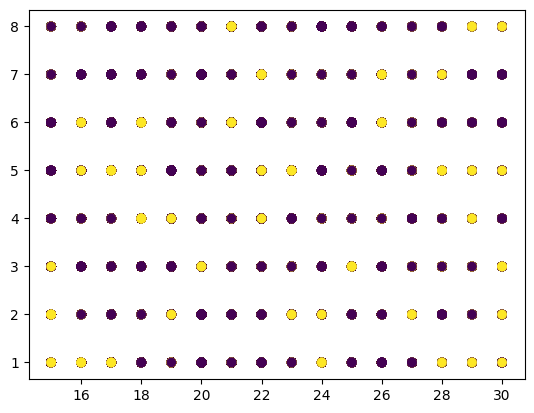

In [62]:
plt.scatter(df['age'],df['semester'],c=df['dropout'])

In [63]:
x=df.iloc[:,0:28]
y=df.iloc[:,-1]

In [64]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.01)

In [65]:
x_train

,age,first_generation,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,course_type,study_mode,semester,...,assignments_submitted_rate,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours
81330,23,1,Middle,0,1,1,17,Law & Social Sciences,Online,6,...,37.6,4,10.6,0,3,8,1,5,66,5.3
18564,18,1,Low,1,1,1,24,STEM,Full-time,1,...,55.6,0,1.0,1,5,10,0,6,1,4.5
12835,21,0,High,0,1,0,0,Health Sciences,Full-time,8,...,85.1,3,6.7,1,2,4,0,9,2,8.0
77127,22,1,High,0,1,1,29,Health Sciences,Full-time,7,...,100.0,3,6.9,1,2,6,0,6,43,6.9
37868,16,1,Middle,0,1,1,13,Arts & Humanities,Full-time,5,...,51.4,1,8.3,0,3,8,1,6,3,7.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53724,27,0,Middle,0,1,1,29,Arts & Humanities,Full-time,1,...,18.7,0,13.2,0,3,10,0,4,39,5.9
69422,23,0,High,0,0,1,15,Law & Social Sciences,Online,4,...,52.1,6,13.6,0,2,5,0,7,28,8.7
62793,21,1,Low,1,1,1,12,Health Sciences,Full-time,2,...,47.3,5,5.7,0,2,7,0,7,1,5.6
52728,15,0,Middle,0,1,1,21,Law & Social Sciences,Online,1,...,92.9,2,17.0,1,11,10,0,7,1,7.3


In [66]:
# Re-split the original data to restore categorical features intact
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.01)

# Verify that original object/categorical columns are restored
print(x_train.dtypes)

age                               int64
first_generation                  int64
family_income_level              object
scholarship_holder                int64
tuition_up_to_date                int64
part_time_job                     int64
weekly_work_hours                 int64
course_type                      object
study_mode                       object
semester                          int64
admission_grade                 float64
previous_qualification_grade    float64
units_enrolled                    int64
units_passed                      int64
units_failed                      int64
gpa_semester_1                  float64
gpa_semester_2                  float64
attendance_rate                 float64
assignments_submitted_rate      float64
library_visits_per_month          int64
lms_logins_per_week             float64
extracurricular_activities        int64
missed_deadlines                  int64
stress_level                      int64
mental_health_support             int64


In [67]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [68]:
# Convert categorical 'object' columns into appropriate numerical dummy variables
categorical_cols = ['family_income_level', 'course_type', 'study_mode']

x_train = pd.get_dummies(x_train, columns=categorical_cols, drop_first=True, dtype=int)
x_test = pd.get_dummies(x_test, columns=categorical_cols, drop_first=True, dtype=int)

# Ensure both train and test have the same aligned columns
x_train, x_test = x_train.align(x_test, join='left', axis=1, fill_value=0)

print("Datatypes after conversion:")
print(x_train.dtypes)

Datatypes after conversion:
age                                    int64
first_generation                       int64
scholarship_holder                     int64
tuition_up_to_date                     int64
part_time_job                          int64
weekly_work_hours                      int64
semester                               int64
admission_grade                      float64
previous_qualification_grade         float64
units_enrolled                         int64
units_passed                           int64
units_failed                           int64
gpa_semester_1                       float64
gpa_semester_2                       float64
attendance_rate                      float64
assignments_submitted_rate           float64
library_visits_per_month               int64
lms_logins_per_week                  float64
extracurricular_activities             int64
missed_deadlines                       int64
stress_level                           int64
mental_health_support      

In [69]:
sc = StandardScaler()
x_train = sc.fit_transform(x_train)


In [70]:
x_train

array([[-0.15316361, -0.85105116,  0.83441663, ...,  1.52236106,
        -0.38548473, -0.53080364],
       [-1.62377665, -0.85105116,  0.83441663, ..., -0.6568744 ,
        -0.38548473, -0.53080364],
       [-1.32965404, -0.85105116,  0.83441663, ..., -0.6568744 ,
        -0.38548473,  1.88393583],
       ...,
       [ 1.02332683,  1.17501749, -1.19844208, ..., -0.6568744 ,
        -0.38548473,  1.88393583],
       [ 0.43508161,  1.17501749,  0.83441663, ..., -0.6568744 ,
        -0.38548473, -0.53080364],
       [-1.32965404,  1.17501749, -1.19844208, ...,  1.52236106,
         2.59413647, -0.53080364]])

In [71]:
x_test=sc.fit_transform(x_test)

In [72]:
from sklearn.linear_model import LogisticRegression
clf=LogisticRegression()
clf.fit(x_train,y_train)

LogisticRegression()

In [73]:
y_predict=clf.predict(x_test)

In [74]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_predict)

0.842

In [75]:
import pickle
pickle.dump(clf,open('model.pkl','wb'))